In [1]:
# Permite importar src/ desde la carpeta notebooks/
import sys
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import DIR_DATA_RAW

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

Variables: 33 · sin futuro: True


,registros
Etiqueta,
mar_sin_faena,52014
busqueda,29668
retorno,25332
ida,21700
espera,20407
cala,19992
puerto,17242
viaje_sin_cala,4730
entrada_cala,3358


Entrenamiento: 126,229 (2025) · Prueba: 14,739 (2026)
F1 macro (prueba 2026): 0.780


,precision,recall,f1-score,support
ida,0.81,0.92,0.86,"1,934.00"
busqueda,0.67,0.45,0.54,"2,664.00"
entrada_cala,0.34,0.71,0.46,294.00
cala,0.84,0.92,0.88,"1,944.00"
salida_cala,0.79,0.94,0.86,296.00
retorno,0.77,0.77,0.77,"2,468.00"
espera,0.95,0.91,0.93,"3,177.00"
puerto,0.91,0.99,0.95,"1,962.00"


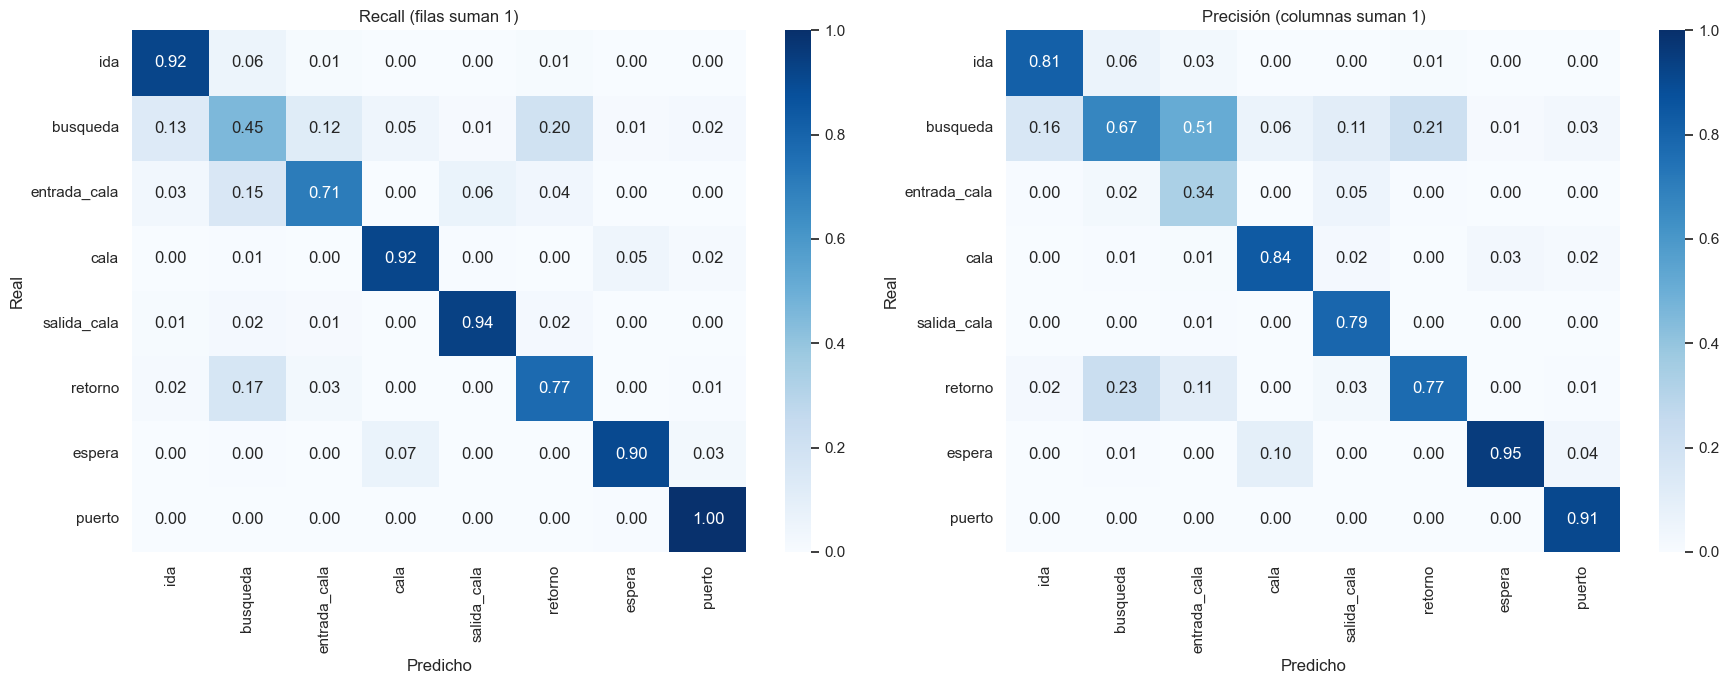

Guardado: C:\Users\srios\Documents\Analisis_Combustible\modelos\actividad_v1.joblib


In [2]:
from src.config import DIR_DATA_PROC, DIR_MODELOS
from src.variables import construir_variables, verificar_sin_futuro, FEATURES, HORAS_HISTORIA
from src.etiquetas import etiquetar_completo
from src.modelo_actividad import CLASES, armar_entrenamiento, entrenar, evaluar
import joblib, datetime

tel_v = pd.read_parquet(DIR_DATA_PROC / "telemetria_viajes.parquet")
vf = pd.read_parquet(DIR_DATA_PROC / "ventanas_calas.parquet")
pu = pd.read_parquet(DIR_DATA_PROC / "paradas_pu.parquet")

tel_f = construir_variables(tel_v)
print("Variables:", len(FEATURES), "· sin futuro:", verificar_sin_futuro(tel_v, n=30))
tel_e = etiquetar_completo(tel_f, vf, pu)
display(tel_e["Etiqueta"].value_counts().to_frame("registros"))
d = armar_entrenamiento(tel_e)

# 1) Evaluación honesta: 2025 -> 2026
train, test = d[d["fecha"] < "2026-01-01"], d[d["fecha"] >= "2026-01-01"]
print(f"Entrenamiento: {len(train):,} (2025) · Prueba: {len(test):,} (2026)")
modelo_eval = entrenar(train)
reporte, cm, macro_f1 = evaluar(modelo_eval, test)
print(f"F1 macro (prueba 2026): {macro_f1:.3f}")
display(reporte.loc[CLASES, ["precision", "recall", "f1-score", "support"]])

y, pred = test["Etiqueta"].astype(str), modelo_eval.predict(test[FEATURES])
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for eje, norm, titulo in [(ax[0], "true", "Recall (filas suman 1)"),
                          (ax[1], "pred", "Precisión (columnas suman 1)")]:
    m = pd.DataFrame(confusion_matrix(y, pred, labels=CLASES, normalize=norm), index=CLASES, columns=CLASES)
    sns.heatmap(m, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=eje)
    eje.set_title(titulo); eje.set_ylabel("Real"); eje.set_xlabel("Predicho")
plt.tight_layout(); plt.show()

# 2) Modelo final: se reentrena con TODO (2025 + 2026) para producción
modelo_final = entrenar(d)
paquete = {
    "modelo": modelo_final,
    "variables": FEATURES,
    "clases": CLASES,
    "horas_historia": HORAS_HISTORIA,
    "version": "actividad_v1",
    "fecha_entrenamiento": datetime.datetime.now().isoformat(timespec="minutes"),
    "datos": f"{d['fecha'].min():%Y-%m-%d} a {d['fecha'].max():%Y-%m-%d} · {len(d):,} registros",
    "metricas_prueba_2026": {"f1_macro": round(macro_f1, 3),
                             "f1_por_clase": reporte.loc[CLASES, "f1-score"].round(3).to_dict()},
}
DIR_MODELOS.mkdir(exist_ok=True)
joblib.dump(paquete, DIR_MODELOS / "actividad_v1.joblib")
tel_e.to_parquet(DIR_DATA_PROC / "telemetria_etiquetada.parquet", index=False)
print("Guardado:", DIR_MODELOS / "actividad_v1.joblib")